In [48]:
from google.colab import drive
import zipfile
import os

drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Colab Notebooks/Projekt i beräkningsvetenskap/Meco/MECO.zip'
extract_path = '/content/MECO'

os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Unzipped")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unzipped


In [49]:
import os
import glob
import pickle
import numpy as np

SOURCE = '/content/MECO/MECO/Video'

# ---------- 1. Find pickle files ----------
if os.path.isfile(SOURCE):
    files = [SOURCE]
else:
    files = sorted(
        glob.glob(os.path.join(SOURCE, '**', '*.pkl'), recursive=True)
        + glob.glob(os.path.join(SOURCE, '**', '*.pickle'), recursive=True)
        + glob.glob(os.path.join(SOURCE, '**', '*.pckl'), recursive=True)
    )

print(f"Found {len(files)} pickle file(s):")
for f in files[:42]:
    print("  ", f, f"({os.path.getsize(f)/1e6:.2f} MB)")
if not files:
    raise SystemExit("No pickle files found, check SOURCE path.")


# ---------- 2. Loader (falls back to pandas / latin1 for old py2 pickles) ----------
def load_pickle(path):
    try:
        with open(path, 'rb') as fh:
            return pickle.load(fh)
    except Exception as e1:
        try:
            import pandas as pd
            return pd.read_pickle(path)
        except Exception as e2:
            with open(path, 'rb') as fh:
                return pickle.load(fh, encoding='latin1')


# ---------- 3. Recursive inspector ----------
def describe(obj, name='root', depth=0, max_depth=4, max_items=15):
    pad = '  ' * depth
    t = type(obj).__name__

    try:
        import pandas as pd
    except ImportError:
        pd = None

    if pd is not None and isinstance(obj, pd.DataFrame):
        print(f"{pad}{name}: DataFrame shape={obj.shape}")
        print(f"{pad}  index: {obj.index.dtype}, {obj.index[:3].tolist()} ...")
        print(f"{pad}  columns ({len(obj.columns)}): {list(obj.columns)}")
        print(f"{pad}  dtypes:\n{obj.dtypes.value_counts().to_string()}")
        print(f"{pad}  head:\n{obj.head().to_string()}")
        au_cols = [c for c in obj.columns if 'au' in str(c).lower()]
        if au_cols:
            print(f"{pad}  AU-like columns ({len(au_cols)}): {au_cols}")
        print(f"{pad}  NaNs per column (non-zero only):")
        nans = obj.isna().sum()
        print(nans[nans > 0].to_string() if (nans > 0).any() else f"{pad}    none")
        print(f"{pad}  describe:\n{obj.describe().T.head(30).to_string()}")

    elif pd is not None and isinstance(obj, pd.Series):
        print(f"{pad}{name}: Series len={len(obj)} dtype={obj.dtype}")
        print(obj.head().to_string())

    elif isinstance(obj, np.ndarray):
        print(f"{pad}{name}: ndarray shape={obj.shape} dtype={obj.dtype}")
        if obj.size and np.issubdtype(obj.dtype, np.number):
            print(f"{pad}  min={np.nanmin(obj):.4g} max={np.nanmax(obj):.4g} "
                  f"mean={np.nanmean(obj):.4g} nans={np.isnan(obj).sum()}")

    elif isinstance(obj, dict):
        print(f"{pad}{name}: dict with {len(obj)} keys")
        keys = list(obj.keys())
        print(f"{pad}  keys (first {max_items}): {keys[:max_items]}")
        if depth < max_depth:
            for k in keys[:max_items]:
                describe(obj[k], name=f"[{k!r}]", depth=depth + 1,
                         max_depth=max_depth, max_items=max_items)

    elif isinstance(obj, (list, tuple)):
        print(f"{pad}{name}: {t} len={len(obj)}")
        if depth < max_depth:
            for i, v in enumerate(obj[:3]):
                describe(v, name=f"[{i}]", depth=depth + 1,
                         max_depth=max_depth, max_items=max_items)

    else:
        r = repr(obj)
        print(f"{pad}{name}: {t} -> {r[:100]}{'...' if len(r) > 100 else ''}")


# ---------- 4. Run on each file ----------
# for path in files[0:1]:   # change/remove the slice to inspect more
path = files[0]
print("\n" + "=" * 80)
print("FILE:", path)
print("=" * 80)
data = load_pickle(path)
describe(data)

Found 42 pickle file(s):
   /content/MECO/MECO/Video/video_S1.pkl (28.18 MB)
   /content/MECO/MECO/Video/video_S10.pkl (27.56 MB)
   /content/MECO/MECO/Video/video_S11.pkl (27.56 MB)
   /content/MECO/MECO/Video/video_S12.pkl (27.37 MB)
   /content/MECO/MECO/Video/video_S13.pkl (24.07 MB)
   /content/MECO/MECO/Video/video_S14.pkl (23.23 MB)
   /content/MECO/MECO/Video/video_S15.pkl (27.41 MB)
   /content/MECO/MECO/Video/video_S16.pkl (27.56 MB)
   /content/MECO/MECO/Video/video_S17.pkl (24.29 MB)
   /content/MECO/MECO/Video/video_S18.pkl (27.67 MB)
   /content/MECO/MECO/Video/video_S19.pkl (27.63 MB)
   /content/MECO/MECO/Video/video_S2.pkl (27.63 MB)
   /content/MECO/MECO/Video/video_S20.pkl (21.32 MB)
   /content/MECO/MECO/Video/video_S21.pkl (27.63 MB)
   /content/MECO/MECO/Video/video_S22.pkl (27.74 MB)
   /content/MECO/MECO/Video/video_S23.pkl (27.92 MB)
   /content/MECO/MECO/Video/video_S24.pkl (27.63 MB)
   /content/MECO/MECO/Video/video_S25.pkl (27.56 MB)
   /content/MECO/MECO/V

In [50]:
print(data['emotion_to_idx_sa']) # Can chose which session to inspect, e.g. session1, session2, session3 or emotion_to_idx_sa
print('--------------------------------')

s1 = data['session1']
s1_keys = list(s1.keys())
print(s1_keys)
print(s1)

Utdata för streaming har trunkerats till de sista 5000 raderna.
        [-2.4900e-01,  8.3000e-02, -4.5000e-02,  3.7000e+01,  9.6300e+01,
          4.9990e+02],
        [-2.5000e-01,  7.9000e-02, -4.5000e-02,  3.7000e+01,  9.6300e+01,
          4.9990e+02],
        [-3.0300e-01,  8.7000e-02, -5.4000e-02,  2.9500e+01,  8.8900e+01,
          5.0290e+02],
        [-2.8700e-01,  9.2000e-02, -5.7000e-02,  2.9400e+01,  8.8400e+01,
          5.0320e+02],
        [-2.7200e-01,  9.2000e-02, -6.1000e-02,  2.9100e+01,  8.7800e+01,
          5.0080e+02],
        [-2.7200e-01,  9.1000e-02, -6.2000e-02,  2.9200e+01,  8.8200e+01,
          5.0240e+02],
        [-2.0200e-01,  7.6000e-02, -7.7000e-02,  2.8000e+01,  9.2800e+01,
          4.9280e+02],
        [-2.2900e-01,  7.2000e-02, -7.3000e-02,  2.7900e+01,  9.2900e+01,
          4.9130e+02],
        [-2.2600e-01,  7.4000e-02, -7.3000e-02,  2.8000e+01,  9.2900e+01,
          4.9130e+02],
        [-2.2200e-01,  7.6000e-02, -7.4000e-02,  2.8000e+01,  9

In [51]:
au = s1['au_openface']
# au_keys = list(s1.keys())
# print(s1_keys)
print('Length of action units:', len(au))
print(au)


Utdata för streaming har trunkerats till de sista 5000 raderna.
         1.0000, 0.0000, 0.6300, 0.0000, 0.0000, 0.1500, 0.1000, 0.0800, 0.0000,
         0.0000, 1.0000, 0.0000, 1.0000, 1.0000, 0.0000, 1.0000, 0.0000, 0.0000,
         0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7300, 0.0000, 1.1900, 0.0000, 1.6600, 3.4200, 0.0000, 1.6700, 0.3300,
         0.6600, 0.1300, 1.0000, 0.5100, 0.3300, 0.9500, 1.1100, 0.1400, 0.0000,
         0.0000, 1.0000, 0.0000, 1.0000, 1.0000, 0.0000, 1.0000, 0.0000, 0.0000,
         0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [2.2200, 0.2600, 0.6400, 0.2300, 1.6600, 3.3900, 0.0000, 1.5500, 0.5400,
         0.3500, 0.1300, 0.8000, 1.1100, 0.3300, 1.6000, 1.1100, 0.0700, 1.0000,
         1.0000, 0.0000, 0.0000, 1.0000, 1.0000, 0.0000, 1.0000, 0.0000, 0.0000,
         0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [3.8300, 0.5600, 0.1100, 0.3900, 1.7200, 3.7300, 0.0000, 1

In [52]:
print(au[0].shape)

torch.Size([16, 35])


In [53]:
labels_vi = s1['label_vi_class']
labels_sa = s1['label_sa_class']
emotions_to_idx = s1['emotion_to_idx_vi']

print(labels_vi)
print(labels_sa)
print(emotions_to_idx)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5]
[5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

# Build dataset

In [54]:
import glob, os, pickle, re
import numpy as np

SOURCE = "/content/MECO/MECO/Video"
MODS = {"au": "au_openface", "hp": "hp_openface", "eg": "gz_openface"}
LABEL_VI, LABEL_SA = "label_vi_class", "label_sa_class"

# Map every name used in the pickles to one canonical name
CANON = {'happy': 'happiness', 'happiness': 'happiness', 'sad': 'sadness', 'sadness': 'sadness',
         'angry': 'angry', 'boredom': 'boredom', 'neutral': 'neutral', 'tension': 'tension'}
ORDER = ['angry', 'boredom', 'happiness', 'neutral', 'sadness', 'tension']
ID = {n: i for i, n in enumerate(ORDER)}


def subject_from_path(path):
    return os.path.splitext(os.path.basename(path))[0]


def find_files(source=SOURCE):
    if os.path.isfile(source):
        return [source]
    pats = ("*.pkl", "*.pickle", "*.pckl")
    return sorted(f for p in pats for f in glob.glob(os.path.join(source, "**", p), recursive=True))


def load_pickle(path):
    with open(path, "rb") as fh:
        return pickle.load(fh)


def build_dataset(files=None, mods=("au",), label="sa", verbose=True):
    """label: 'sa' = self-reported emotion (recommended), 'vi' = intended stimulus emotion.
    Both are converted to names first, so they mean the same thing in every session."""
    files = files or find_files()
    parts = []
    for path in files:
        raw = load_pickle(path)
        sid = subject_from_path(path)
        sa_name = {v: CANON[k] for k, v in raw["emotion_to_idx_sa"].items()}
        sessions = sorted(k for k in raw if re.fullmatch(r"session\d+", str(k)))
        for sess in sessions:
            s = raw[sess]
            vi_name = {v: CANON[k] for k, v in s["emotion_to_idx_vi"].items()}   # per session!
            y_vi = np.asarray(s[LABEL_VI]).astype(int).ravel()
            y_stim = np.array([ID[vi_name[v]] for v in y_vi])
            y_self = np.array([ID[sa_name[int(v)]] for v in np.asarray(s[LABEL_SA]).astype(int).ravel()])
            y = y_self if label == "sa" else y_stim

            part = {}
            for m in mods:
                a = np.asarray(s[MODS[m]], dtype=np.float32)
                assert a.ndim == 3 and a.shape[0] == len(y_vi), \
                    f"{path}/{sess}/{MODS[m]}: expected (n,16,F) with n={len(y_vi)}, got {a.shape}"
                a[np.all(a == 0, axis=-1)] = np.nan      # failed detection -> missing
                part[m] = a
            part.update(
                y=y, y_vi=y_vi, y_stim=y_stim, y_self=y_self,
                valence=np.asarray(s["label_valence"], dtype=float).ravel(),
                arousal=np.asarray(s["label_arousal"], dtype=float).ravel(),
                subject=np.full(len(y), sid),
                session=np.full(len(y), int(re.search(r"\d+", sess).group())),
                trial=trial_ids_from_labels(y_vi),       # same trial definition as before
            )
            parts.append(part)

    data = concat_subjects(parts)
    if verbose:
        print(f"files: {len(files)} | subjects: {len(np.unique(data['subject']))} "
              f"| windows: {len(data['y'])} | trials: {len(np.unique(data['trial']))}")
        print("label:", label, "| class counts:", np.bincount(data["y"], minlength=len(ORDER)).tolist())
        print("classes:", ORDER)
        print("missing frame fraction:", {m: float(np.isnan(data[m]).mean()) for m in mods})
    return data

In [55]:
"""
Simple MLP baseline for MECO window features.

  (N,16,F) frames  ->  per-window stats (mean, std, min, max, mean |delta|)  ->  MLP  ->  classes

Expects `data` from build_dataset(...) after normalize_per_subject(...):
    data[mod]: (N,16,F), data['y'], data['subject'], data['trial']
"""
import copy
import warnings

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import GroupKFold


def get_device():
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():  # Apple-silicon GPU
        return "mps"
    return "cpu"


def window_features(data, mods=("au",)):
    """(N,T,F) per modality -> (N, 5*F) stats per modality, concatenated.
    NaN frames (failed detections) are ignored; an all-NaN window becomes zeros."""
    feats = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        for m in mods:
            a = data[m]
            feats += [np.nanmean(a, 1), np.nanstd(a, 1), np.nanmin(a, 1), np.nanmax(a, 1),
                      np.nanmean(np.abs(np.diff(a, axis=1)), 1)]
    return np.nan_to_num(np.concatenate(feats, 1)).astype(np.float32)


class SimpleMLP(nn.Module):
    def __init__(self, in_dim, n_classes, hidden=128, drop=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hidden, hidden // 2), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hidden // 2, n_classes))

    def forward(self, x):
        return self.net(x)


@torch.no_grad()
def _evaluate(model, X, y, crit, chunk=4096):
    model.eval()
    logits = torch.cat([model(X[i:i + chunk]) for i in range(0, len(X), chunk)])
    p, yy = logits.argmax(-1).cpu().numpy(), y.cpu().numpy()
    return {"loss": crit(logits, y).item(),
            "UAR": recall_score(yy, p, average="macro", zero_division=0),
            "WAR": accuracy_score(yy, p)}


def _shuffle_trial_labels(y, trial, rng):
    """Control: permute labels across trials (labels stay constant within a trial)."""
    trials = np.unique(trial)
    lab = np.array([y[trial == t][0] for t in trials])
    mapping = dict(zip(trials, rng.permutation(lab)))
    return np.array([mapping[t] for t in trial])


def train_cv_mlp(data, n_classes, mods=("au",), folds=5, epochs=60, bs=128, lr=1e-3, wd=1e-2,
                 hidden=128, drop=0.3, noise=0.05, seed=0, dev=None,
                 shuffle_labels=False, print_every=1):
    dev = dev or get_device()
    X_all, y_all = window_features(data, mods), np.asarray(data["y"])
    subj, trial = np.asarray(data["subject"]), np.asarray(data["trial"])
    rng = np.random.default_rng(seed)
    print(f"device: {dev} | features: {X_all.shape} | subjects: {len(np.unique(subj))} "
          f"| windows: {len(y_all)} | trials: {len(np.unique(trial))}")
    if shuffle_labels:
        print("!! CONTROL RUN: labels shuffled across trials, expect chance-level scores")
        y_all = _shuffle_trial_labels(y_all, trial, rng)

    results, histories, baselines = [], [], []
    for f, (tr, te) in enumerate(GroupKFold(folds).split(X_all, groups=subj)):
        tr_subj = rng.permutation(np.unique(subj[tr]))
        val_subj = tr_subj[: max(1, int(0.15 * len(tr_subj)))]
        is_val = np.isin(subj[tr], val_subj)
        va, tr = tr[is_val], tr[~is_val]

        for a, b, name in [(tr, te, "train/test"), (tr, va, "train/val"), (va, te, "val/test")]:
            assert not set(subj[a]) & set(subj[b]), f"subject overlap {name}"
            assert not set(trial[a]) & set(trial[b]), f"trial overlap {name}"
        base = (y_all[te] == np.bincount(y_all[tr], minlength=n_classes).argmax()).mean()
        baselines.append(base)
        print(f"\n=== fold {f} | train {len(tr)} ({len(set(subj[tr]))} subj) | val {len(va)} | "
              f"test {len(te)} ({len(set(subj[te]))} subj) | majority-class WAR on test: {base:.3f}")

        # standardise with TRAIN statistics only
        mu, sd = X_all[tr].mean(0), X_all[tr].std(0) + 1e-6
        T = lambda idx: torch.from_numpy((X_all[idx] - mu) / sd).to(dev)
        Y = lambda idx: torch.from_numpy(y_all[idx]).long().to(dev)
        Xtr, Xva, Xte, ytr, yva, yte = T(tr), T(va), T(te), Y(tr), Y(va), Y(te)

        torch.manual_seed(seed + f)
        model = SimpleMLP(X_all.shape[1], n_classes, hidden, drop).to(dev)
        counts = np.bincount(y_all[tr], minlength=n_classes).astype(np.float32)
        w = torch.tensor(counts.sum() / (n_classes * np.maximum(counts, 1)),
                         dtype=torch.float32, device=dev)
        crit = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)

        fold_history = {"train_loss": [], "val_loss": [], "val_uar": [], "val_war": []}
        best, best_ep, best_state = np.inf, 0, None
        for ep in range(epochs):
            model.train()
            perm = torch.randperm(len(Xtr), device=dev)
            tl, tc = 0.0, 0
            for i in range(0, len(perm), bs):
                idx = perm[i:i + bs]
                xb, yb = Xtr[idx], ytr[idx]
                if noise > 0:
                    xb = xb + noise * torch.randn_like(xb)
                logits = model(xb)
                loss = crit(logits, yb)
                opt.zero_grad()
                loss.backward()
                opt.step()
                tl += loss.item() * len(idx)
                tc += (logits.argmax(-1) == yb).sum().item()
            sched.step()

            v = _evaluate(model, Xva, yva, crit)
            fold_history["train_loss"].append(tl / len(Xtr))
            fold_history["val_loss"].append(v["loss"])
            fold_history["val_uar"].append(v["UAR"])
            fold_history["val_war"].append(v["WAR"])

            mark = ""
            if v["loss"] < best:
                best, best_ep, best_state = v["loss"], ep + 1, copy.deepcopy(model.state_dict())
                mark = " *"
            if (ep + 1) % print_every == 0 or mark:
                print(f"fold {f} ep {ep + 1:02d}/{epochs} | train loss {tl / len(Xtr):.3f} "
                      f"acc {tc / len(Xtr):.3f} | val loss {v['loss']:.3f} "
                      f"UAR {v['UAR']:.3f} WAR {v['WAR']:.3f}{mark}")
        model.load_state_dict(best_state)
        r = _evaluate(model, Xte, yte, crit)
        model.eval()
        with torch.no_grad():
            p = torch.softmax(model(Xte), -1).cpu().numpy()
        tt, yt = trial[te], y_all[te]
        ids = np.unique(tt)
        clip_pred = np.array([p[tt == t].mean(0).argmax() for t in ids])
        clip_true = np.array([np.bincount(yt[tt == t], minlength=n_classes).argmax() for t in ids])
        clip_uar = recall_score(clip_true, clip_pred, average="macro", zero_division=0)
        print(f"fold {f} CLIP-LEVEL UAR {clip_uar:.3f} over {len(ids)} clips")
        print(f"fold {f} TEST (best val epoch {best_ep}): UAR {r['UAR']:.3f} WAR {r['WAR']:.3f} "
              f"(majority {base:.3f})")
        results.append(r)
        histories.append(fold_history)

    print("\nmean test UAR %.3f | WAR %.3f | majority-class WAR %.3f" % (
        np.mean([r["UAR"] for r in results]), np.mean([r["WAR"] for r in results]),
        np.mean(baselines)))
    return results, histories

In [56]:
data = build_dataset(mods=("au",), label="sa")
assert len(set(data["subject"])) == 42
data = normalize_per_subject(data, mods=("au",))


files: 42 | subjects: 42 | windows: 30592 | trials: 733
label: sa | class counts: [3548, 2041, 6344, 6889, 7196, 4574]
classes: ['angry', 'boredom', 'happiness', 'neutral', 'sadness', 'tension']
missing frame fraction: {'au': 0.09454269089958159}


In [57]:
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import recall_score

y = np.asarray(data["y"])
subj = np.asarray(data["subject"])
sess = np.asarray(data["session"])
X = window_features(data, ("au",))
session_onehot = np.eye(3)[sess - 1]

def cv_uar(features, target):
    scores = []
    for tr, te in GroupKFold(5).split(features, groups=subj):
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=2000, class_weight="balanced"))
        clf.fit(features[tr], target[tr])
        scores.append(recall_score(target[te], clf.predict(features[te]),
                                   average="macro", zero_division=0))
    return round(float(np.mean(scores)), 3), round(float(np.std(scores)), 3)

print("session index only -> self-report UAR:", cv_uar(session_onehot, y))
print("AU features -> session UAR (3 classes):", cv_uar(X, sess))
print("AU features -> self-report UAR (logistic):", cv_uar(X, y))

session index only -> self-report UAR: (0.217, 0.02)
AU features -> session UAR (3 classes): (0.331, 0.06)
AU features -> self-report UAR (logistic): (0.213, 0.01)


In [58]:
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import recall_score

y = np.asarray(data["y"]); subj = np.asarray(data["subject"])
sess = np.asarray(data["session"]); trial = np.asarray(data["trial"])
X = window_features(data, ("au",))
session_onehot = np.eye(3)[sess - 1]

def within_session_shuffle(y, trial, sess, rng):
    out = y.copy()
    for s in np.unique(sess):
        m = sess == s
        tids = np.unique(trial[m])
        lab = np.array([y[trial == t][0] for t in tids])
        perm = dict(zip(tids, rng.permutation(lab)))
        out[m] = [perm[t] for t in trial[m]]
    return out

def cv_uar(features, target):
    scores = []
    for tr, te in GroupKFold(5).split(features, groups=subj):
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=2000, class_weight="balanced"))
        clf.fit(features[tr], target[tr])
        scores.append(recall_score(target[te], clf.predict(features[te]),
                                   average="macro", zero_division=0))
    return round(float(np.mean(scores)), 3), round(float(np.std(scores)), 3)

print("session only:             ", cv_uar(session_onehot, y))
print("AU real labels:           ", cv_uar(X, y))
rng = np.random.default_rng(0)
shuf = [cv_uar(X, within_session_shuffle(y, trial, sess, rng)) for _ in range(3)]
print("AU within-session shuffle:", shuf)

session only:              (0.217, 0.02)
AU real labels:            (0.213, 0.01)
AU within-session shuffle: [(0.153, 0.019), (0.154, 0.012), (0.188, 0.016)]


In [59]:
data['trial']

array([  0,   0,   0, ..., 732, 732, 732], shape=(30592,))

In [60]:
import matplotlib.pyplot as plt

def plot_training_history(fold_histories):
    """
    Plots training loss, validation loss, and validation metrics (UAR/WAR) across epochs.

    Args:
        fold_histories (list of dict): A list where each element is a dictionary containing
                                       logged metrics for each epoch in that fold.
    """
    num_folds = len(fold_histories)
    fig, axes = plt.subplots(num_folds, 2, figsize=(14, 4 * num_folds), sharex=True)
    if num_folds == 1:
        axes = np.expand_dims(axes, 0)

    for f, history in enumerate(fold_histories):
        epochs = range(1, len(history['train_loss']) + 1)

        # Plot Losses
        axes[f, 0].plot(epochs, history['train_loss'], label='Train Loss', color='royalblue')
        axes[f, 0].plot(epochs, history['val_loss'], label='Val Loss', color='orange')
        axes[f, 0].set_title(f'Fold {f} - Loss History')
        axes[f, 0].set_ylabel('Loss')
        axes[f, 0].grid(True, linestyle='--', alpha=0.6)
        axes[f, 0].legend()

        # Plot Accuracies
        axes[f, 1].plot(epochs, history['val_uar'], label='Val UAR', color='forestgreen')
        axes[f, 1].plot(epochs, history['val_war'], label='Val WAR', color='crimson')
        axes[f, 1].set_title(f'Fold {f} - Validation Metrics')
        axes[f, 1].set_ylabel('Score')
        axes[f, 1].grid(True, linestyle='--', alpha=0.6)
        axes[f, 1].legend()

    plt.xlabel('Epochs')
    plt.tight_layout()
    plt.show()

device: cpu | features: (30592, 175) | subjects: 42 | windows: 30592 | trials: 733

=== fold 0 | train 21087 (29 subj) | val 3609 | test 5896 (8 subj) | majority-class WAR on test: 0.211
fold 0 ep 01/30 | train loss 1.776 acc 0.235 | val loss 1.874 UAR 0.195 WAR 0.224 *
fold 0 ep 02/30 | train loss 1.700 acc 0.309 | val loss 1.900 UAR 0.178 WAR 0.198
fold 0 ep 03/30 | train loss 1.660 acc 0.337 | val loss 1.899 UAR 0.189 WAR 0.217
fold 0 ep 04/30 | train loss 1.621 acc 0.361 | val loss 1.899 UAR 0.206 WAR 0.233
fold 0 ep 05/30 | train loss 1.592 acc 0.380 | val loss 1.910 UAR 0.209 WAR 0.241
fold 0 ep 06/30 | train loss 1.558 acc 0.397 | val loss 1.916 UAR 0.214 WAR 0.238
fold 0 ep 07/30 | train loss 1.542 acc 0.411 | val loss 1.941 UAR 0.202 WAR 0.229
fold 0 ep 08/30 | train loss 1.514 acc 0.426 | val loss 1.965 UAR 0.209 WAR 0.237
fold 0 ep 09/30 | train loss 1.504 acc 0.427 | val loss 1.962 UAR 0.203 WAR 0.229
fold 0 ep 10/30 | train loss 1.485 acc 0.442 | val loss 1.958 UAR 0.209 W

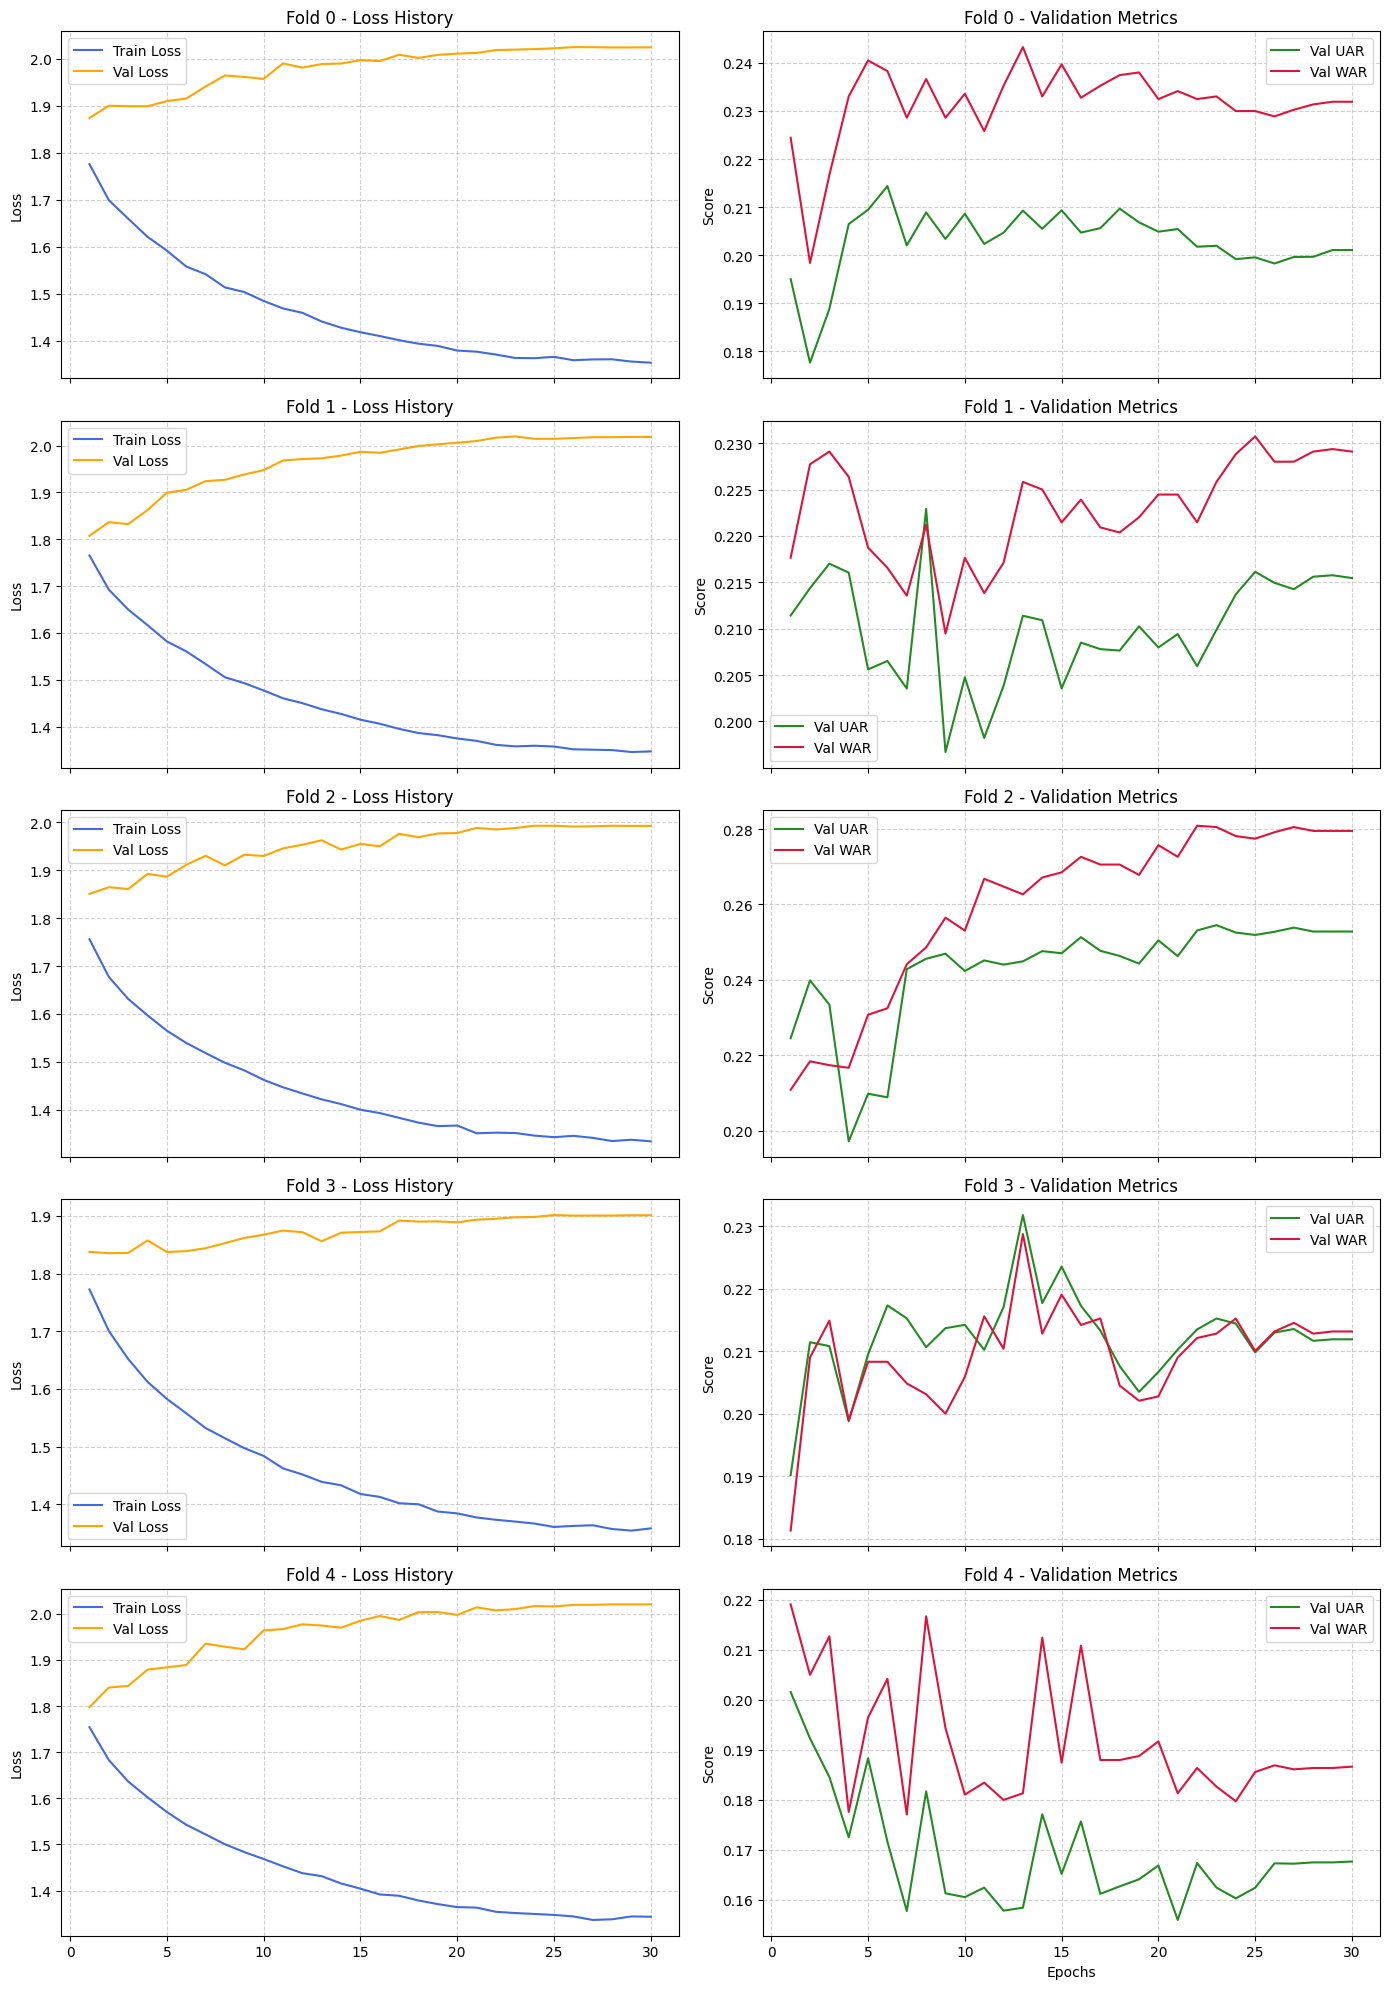

In [61]:
# Run the training process and retrieve both test results and training histories
results, histories = train_cv_mlp(data, n_classes=6, epochs=30, mods=("au", ),shuffle_labels=False)

# Visualize the training vs validation history
plot_training_history(histories)